In [ ]:
!pip install -q opencv-contrib-python-headless scikit-image matplotlib pandas


In [ ]:
import torch
import torchvision
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage

print("=" * 45)
print("ENVIRONMENT CHECK")
print("=" * 45)

print("Python libraries loaded successfully!")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("OpenCV:", cv2.__version__)
print("Scikit-image:", skimage.__version__)

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

print("=" * 45)

ENVIRONMENT CHECK
Python libraries loaded successfully!
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
OpenCV: 4.14.0
Scikit-image: 0.25.2
GPU available: True
GPU: Tesla T4


In [ ]:
import os

BASE_DIR = "/content/rcnn_comparison"

DATA_DIR = os.path.join(BASE_DIR, "data", "sample_images")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
DETECTION_DIR = os.path.join(OUTPUT_DIR, "detections")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(DETECTION_DIR, exist_ok=True)
os.makedirs(PLOT_DIR, exist_ok=True)

print("Project folders created!")
print("Dataset:", DATA_DIR)
print("Detections:", DETECTION_DIR)
print("Plots:", PLOT_DIR)

Project folders created!
Dataset: /content/rcnn_comparison/data/sample_images
Detections: /content/rcnn_comparison/outputs/detections
Plots: /content/rcnn_comparison/outputs/plots


In [ ]:
import requests
from PIL import Image
from io import BytesIO
import os

image_urls = {
    "bus.jpg": "https://ultralytics.com/images/bus.jpg",
    "zidane.jpg": "https://ultralytics.com/images/zidane.jpg"
}

for filename, url in image_urls.items():
    save_path = os.path.join(DATA_DIR, filename)

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    image = Image.open(BytesIO(response.content)).convert("RGB")
    image.save(save_path)

    print(f"Successfully downloaded: {filename}")
    print(f"Image dimensions: {image.size}")
    print("-" * 35)

print("Dataset files:", os.listdir(DATA_DIR))

Successfully downloaded: bus.jpg
Image dimensions: (810, 1080)
-----------------------------------
Successfully downloaded: zidane.jpg
Image dimensions: (1280, 720)
-----------------------------------
Dataset files: ['bus.jpg', 'zidane.jpg']


In [1]:
import os
from PIL import Image
import matplotlib.pyplot as plt

image_files = sorted(os.listdir(DATA_DIR))

plt.figure(figsize=(14, 6))

for i, filename in enumerate(image_files):
    image = Image.open(os.path.join(DATA_DIR, filename))

    plt.subplot(1, len(image_files), i + 1)
    plt.imshow(image)
    plt.title(f"{filename}\n{image.size}")
    plt.axis("off")

plt.tight_layout()
plt.show()

NameError: name 'DATA_DIR' is not defined

In [2]:
import os

BASE_DIR = "/content/rcnn_comparison"
DATA_DIR = os.path.join(BASE_DIR, "data", "sample_images")

print("Dataset folder:", DATA_DIR)
print("Folder exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("Files found:", os.listdir(DATA_DIR))
else:
    os.makedirs(DATA_DIR, exist_ok=True)
    print("Dataset folder recreated.")

Dataset folder: /content/rcnn_comparison/data/sample_images
Folder exists: False
Dataset folder recreated.


In [3]:
import os
import requests
from PIL import Image
from io import BytesIO

BASE_DIR = "/content/rcnn_comparison"
DATA_DIR = os.path.join(BASE_DIR, "data", "sample_images")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
DETECTION_DIR = os.path.join(OUTPUT_DIR, "detections")
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")

# Create directories
for folder in [DATA_DIR, DETECTION_DIR, PLOT_DIR]:
    os.makedirs(folder, exist_ok=True)

# Image sources
images = {
    "bus.jpg": "https://ultralytics.com/images/bus.jpg",
    "zidane.jpg": "https://ultralytics.com/images/zidane.jpg"
}

# Download images
for filename, url in images.items():
    filepath = os.path.join(DATA_DIR, filename)

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    img = Image.open(BytesIO(response.content)).convert("RGB")
    img.save(filepath)

    print(f"Downloaded: {filename} | Size: {img.size}")

print("\nDataset files:", os.listdir(DATA_DIR))

Downloaded: bus.jpg | Size: (810, 1080)
Downloaded: zidane.jpg | Size: (1280, 720)

Dataset files: ['bus.jpg', 'zidane.jpg']


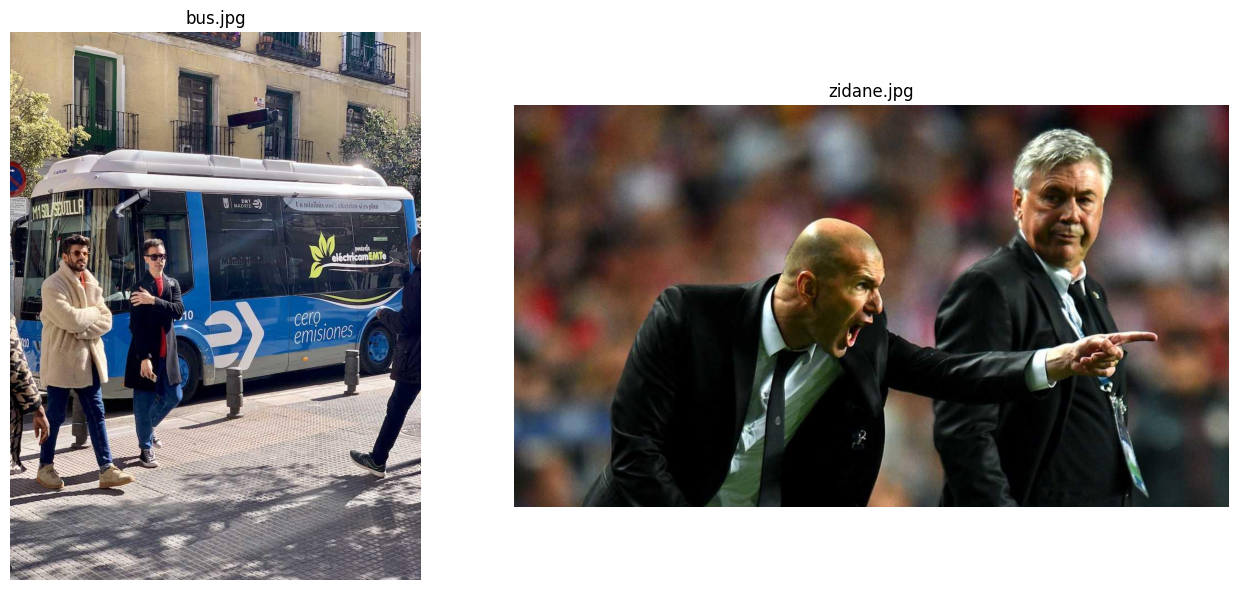

In [4]:
from PIL import Image
import matplotlib.pyplot as plt
import os

image_files = sorted(os.listdir(DATA_DIR))

fig, axes = plt.subplots(1, len(image_files), figsize=(14, 6))

if len(image_files) == 1:
    axes = [axes]

for ax, filename in zip(axes, image_files):
    img = Image.open(os.path.join(DATA_DIR, filename))
    ax.imshow(img)
    ax.set_title(filename)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
import requests
from PIL import Image
from io import BytesIO
import os

additional_images = {
    "street.jpg": "https://ultralytics.com/images/street.jpg",
    "sports.jpg": "https://ultralytics.com/images/sports.jpg",
    "animals.jpg": "https://ultralytics.com/images/zebra.jpg"
}

for filename, url in additional_images.items():
    try:
        response = requests.get(url, timeout=30)
        response.raise_for_status()

        img = Image.open(BytesIO(response.content)).convert("RGB")
        img.save(os.path.join(DATA_DIR, filename))
        print(f"Downloaded: {filename} | Size: {img.size}")

    except Exception as e:
        print(f"Failed: {filename} | {e}")

print("\nFinal dataset:", os.listdir(DATA_DIR))

Failed: street.jpg | 404 Client Error: Not Found for url: https://github.com/ultralytics/assets/releases/download/v0.0.0/street.jpg
Failed: sports.jpg | 404 Client Error: Not Found for url: https://github.com/ultralytics/assets/releases/download/v0.0.0/sports.jpg
Failed: animals.jpg | 404 Client Error: Not Found for url: https://github.com/ultralytics/assets/releases/download/v0.0.0/zebra.jpg

Final dataset: ['bus.jpg', 'zidane.jpg']


In [6]:
import os
import requests
from PIL import Image
from io import BytesIO

DATA_DIR = "/content/rcnn_comparison/data/sample_images"

candidates = {
    "image3.jpg": "https://images.unsplash.com/photo-1494972308805-463bc619d34e?w=800",
    "image4.jpg": "https://images.unsplash.com/photo-1517849845537-4d257902454a?w=800",
    "image5.jpg": "https://images.unsplash.com/photo-1519681393784-d120267933ba?w=800"
}

for filename, url in candidates.items():
    try:
        response = requests.get(url, timeout=25)
        response.raise_for_status()

        img = Image.open(BytesIO(response.content))
        img.verify()  # Confirm valid image

        # Reopen after verification and save
        img = Image.open(BytesIO(response.content)).convert("RGB")
        img.save(os.path.join(DATA_DIR, filename))

        print(f"SUCCESS: {filename} | {img.size}")

    except Exception as e:
        print(f"FAILED: {filename} | {e}")

print("\nFiles currently available:")
print(sorted(os.listdir(DATA_DIR)))

SUCCESS: image3.jpg | (800, 532)
SUCCESS: image4.jpg | (800, 1067)
SUCCESS: image5.jpg | (800, 534)

Files currently available:
['bus.jpg', 'image3.jpg', 'image4.jpg', 'image5.jpg', 'zidane.jpg']


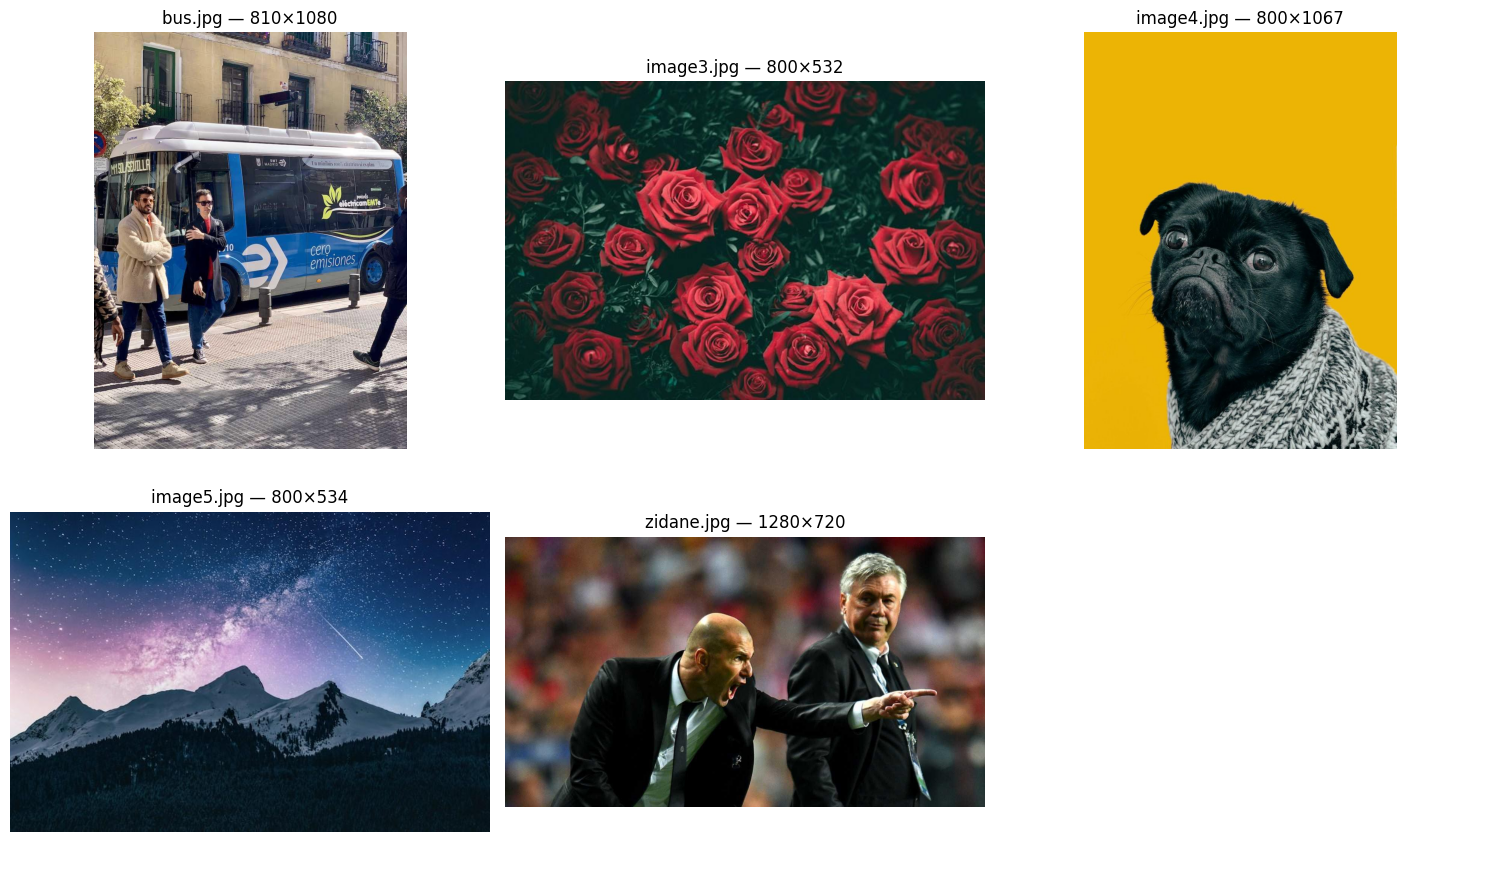

Total test images: 5


In [7]:
import os
from PIL import Image
import matplotlib.pyplot as plt

DATA_DIR = "/content/rcnn_comparison/data/sample_images"

files = sorted([
    f for f in os.listdir(DATA_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(files):
        filename = files[i]
        img = Image.open(os.path.join(DATA_DIR, filename))
        ax.imshow(img)
        ax.set_title(f"{filename} — {img.width}×{img.height}")
    ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Total test images: {len(files)}")

In [8]:
import torch
import torchvision
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
from PIL import Image, ImageDraw
import os
import time

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# Load pretrained model
weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn(weights=weights)
model.to(device)
model.eval()

# COCO labels
COCO_CLASSES = weights.meta["categories"]

# Output directory
OUTPUT_DIR = "/content/rcnn_comparison/outputs"
DETECTION_DIR = os.path.join(OUTPUT_DIR, "detections")
os.makedirs(DETECTION_DIR, exist_ok=True)

print("Model loaded successfully!")
print("Number of COCO classes:", len(COCO_CLASSES))

Device: cuda
Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


100%|██████████| 160M/160M [00:00<00:00, 168MB/s]


Model loaded successfully!
Number of COCO classes: 91


In [9]:
import os
import torch
import time
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from torchvision.transforms.functional import to_tensor

DATA_DIR = "/content/rcnn_comparison/data/sample_images"
OUTPUT_DIR = "/content/rcnn_comparison/outputs"
DETECTION_DIR = os.path.join(OUTPUT_DIR, "detections")
os.makedirs(DETECTION_DIR, exist_ok=True)

# Confidence threshold
CONFIDENCE_THRESHOLD = 0.50

# Warm-up (excluded from timing)
dummy = torch.rand(3, 600, 600).to(device)
with torch.no_grad():
    model([dummy])
if torch.cuda.is_available():
    torch.cuda.synchronize()

all_results = []
summary_results = []

image_files = sorted([
    f for f in os.listdir(DATA_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

for filename in image_files:
    image_path = os.path.join(DATA_DIR, filename)
    image = Image.open(image_path).convert("RGB")
    image_tensor = to_tensor(image).to(device)

    # Measure inference time
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.no_grad():
        prediction = model([image_tensor])[0]

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inference_time = (time.perf_counter() - start_time) * 1000

    boxes = prediction["boxes"].cpu()
    labels = prediction["labels"].cpu()
    scores = prediction["scores"].cpu()

    # Keep detections above threshold
    keep = scores >= CONFIDENCE_THRESHOLD
    boxes = boxes[keep]
    labels = labels[keep]
    scores = scores[keep]

    # Draw annotations
    annotated = image.copy()
    draw = ImageDraw.Draw(annotated)

    for box, label, score in zip(boxes, labels, scores):
        x1, y1, x2, y2 = box.tolist()
        class_name = COCO_CLASSES[int(label)]
        confidence = float(score)

        draw.rectangle([x1, y1, x2, y2], outline="red", width=3)
        draw.text(
            (x1, max(0, y1 - 18)),
            f"{class_name} {confidence:.2f}",
            fill="yellow",
            stroke_width=1,
            stroke_fill="black"
        )

        all_results.append({
            "image": filename,
            "class": class_name,
            "confidence": confidence,
            "x1": x1, "y1": y1, "x2": x2, "y2": y2,
            "inference_ms": inference_time
        })

    # Save annotated image
    save_path = os.path.join(DETECTION_DIR, f"detected_{filename}")
    annotated.save(save_path)

    summary_results.append({
        "image": filename,
        "objects_detected": len(boxes),
        "inference_time_ms": round(inference_time, 2)
    })

    print(f"{filename}: {len(boxes)} objects | {inference_time:.2f} ms")

# Save CSVs
detections_df = pd.DataFrame(all_results)
summary_df = pd.DataFrame(summary_results)

detections_df.to_csv(os.path.join(OUTPUT_DIR, "faster_rcnn_detections.csv"), index=False)
summary_df.to_csv(os.path.join(OUTPUT_DIR, "faster_rcnn_summary.csv"), index=False)

print("\n--- DETECTION SUMMARY ---")
display(summary_df)

print("\n--- DETECTED OBJECTS ---")
display(detections_df[["image", "class", "confidence"]])

print("\nSaved detections to:", DETECTION_DIR)

bus.jpg: 5 objects | 163.81 ms
image3.jpg: 0 objects | 182.23 ms
image4.jpg: 1 objects | 100.02 ms
image5.jpg: 0 objects | 110.79 ms
zidane.jpg: 9 objects | 118.16 ms

--- DETECTION SUMMARY ---


,image,objects_detected,inference_time_ms
0,bus.jpg,5,163.81
1,image3.jpg,0,182.23
2,image4.jpg,1,100.02
3,image5.jpg,0,110.79
4,zidane.jpg,9,118.16



--- DETECTED OBJECTS ---


,image,class,confidence
0,bus.jpg,person,0.998574
1,bus.jpg,person,0.996333
2,bus.jpg,bus,0.990633
3,bus.jpg,person,0.982977
4,bus.jpg,person,0.968243
5,image4.jpg,dog,0.995463
6,zidane.jpg,person,0.992827
7,zidane.jpg,person,0.984350
8,zidane.jpg,tie,0.962424
9,zidane.jpg,tie,0.927588



Saved detections to: /content/rcnn_comparison/outputs/detections


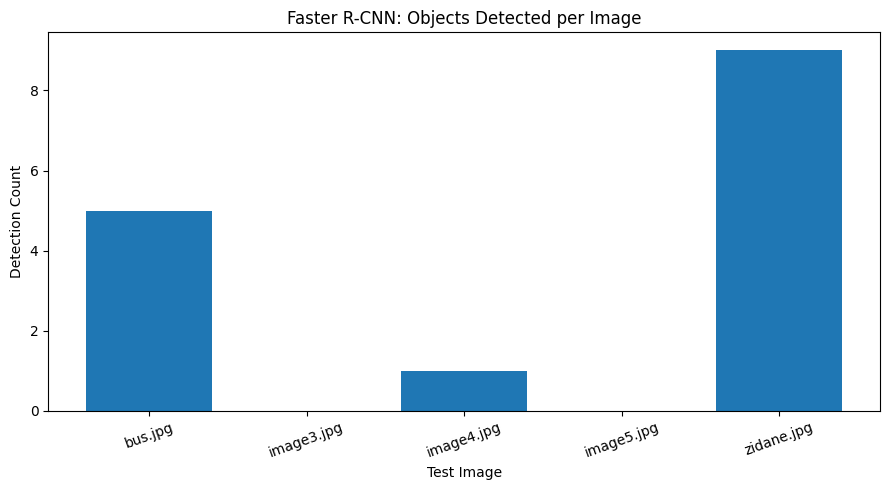

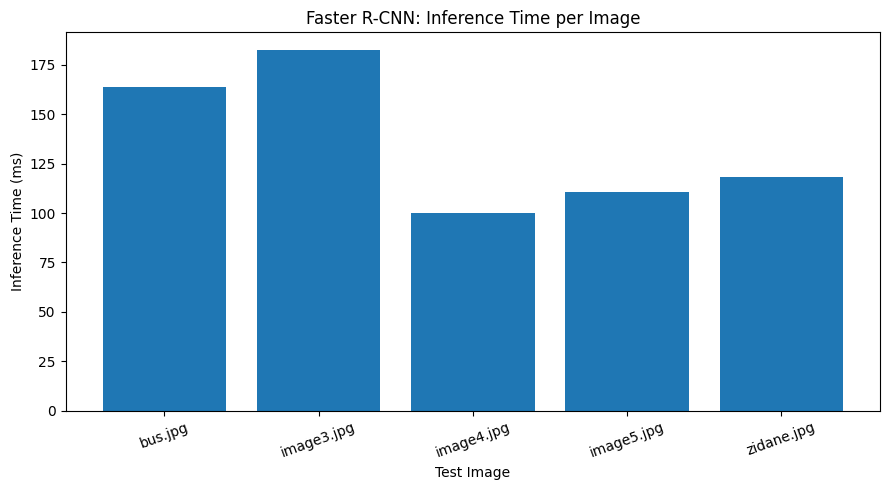

Plots saved: ['detection_counts.png', 'inference_times.png']
Average inference time: 135.0 ms
Average detections: 3.0


In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import os

OUTPUT_DIR = "/content/rcnn_comparison/outputs"
PLOT_DIR = os.path.join(OUTPUT_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

df = pd.read_csv(os.path.join(OUTPUT_DIR, "faster_rcnn_summary.csv"))

# Detection count plot
plt.figure(figsize=(9, 5))
plt.bar(df["image"], df["objects_detected"])
plt.title("Faster R-CNN: Objects Detected per Image")
plt.xlabel("Test Image")
plt.ylabel("Detection Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "detection_counts.png"), dpi=300)
plt.show()

# Inference time plot
plt.figure(figsize=(9, 5))
plt.bar(df["image"], df["inference_time_ms"])
plt.title("Faster R-CNN: Inference Time per Image")
plt.xlabel("Test Image")
plt.ylabel("Inference Time (ms)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "inference_times.png"), dpi=300)
plt.show()

print("Plots saved:", os.listdir(PLOT_DIR))
print("Average inference time:", round(df["inference_time_ms"].mean(), 2), "ms")
print("Average detections:", round(df["objects_detected"].mean(), 2))

In [ ]:
import os
import pandas as pd

faster_dir = f"{OUTPUT_DIR}"

detections_file = f"{faster_dir}/faster_rcnn_detections.csv"
summary_file = f"{faster_dir}/faster_rcnn_summary.csv"

print("Detection results file exists:", os.path.exists(detections_file))
print("Summary file exists:", os.path.exists(summary_file))

if os.path.exists(detections_file):
    faster_detections = pd.read_csv(detections_file)
    display(faster_detections.head(10))

if os.path.exists(summary_file):
    faster_summary = pd.read_csv(summary_file)
    display(faster_summary)